# Notebook 5: Post-hoc Uncertainty and Abstention Methods

This notebook compares several post-hoc confidence scores for distinguishing in-distribution (ID) examples from out-of-distribution (OOD) inputs using the trained models and saved logits from the previous notebooks. The models are not retrained; instead, different uncertainty measures are calculated from their existing outputs after inference.

The methods evaluated are Maximum Softmax Probability (MSP), normalized entropy, prediction margin, and energy. Each method summarizes the model's certainty in a different way. For consistent comparison, the scores are oriented so that higher values indicate more ID-like or more confident predictions, including transforming entropy and energy when necessary. MSP serves as the abstention baseline.

The notebook evaluates how well these scores separate ID and OOD examples using AUROC, AUPR, and the false-positive rate at approximately 95% ID coverage. It also selects thresholds using ID confidence scores only and measures the proportion of OOD examples rejected at that fixed coverage level. This evaluates the practical trade-off between retaining familiar inputs and rejecting unfamiliar ones.

These are post-hoc threshold-based baselines rather than newly trained abstention models. No separate rejection network is fitted. Instead, the results estimate how each confidence score could support a decision rule in which high-confidence predictions are accepted and low-confidence predictions are rejected or treated as abstentions. The comparison identifies which score provides the most useful basis for the later abstention analysis.

## Import Libraries

In [3]:
from pathlib import Path
import torch
import pandas as pd
import numpy as np

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    roc_curve,
)

## Load Saved Logits

In [4]:
LOGIT_DIR = Path("./logits")
RESULT_DIR = Path("./results")

mobile_id = torch.load(
    LOGIT_DIR / "mobilenet_id_seed42.pt",
    map_location="cpu",
)

mobile_grape = torch.load(
    LOGIT_DIR / "mobilenet_grape_seed42.pt",
    map_location="cpu",
)

mobile_corn = torch.load(
    LOGIT_DIR / "mobilenet_corn_seed42.pt",
    map_location="cpu",
)

mobile_nonplant = torch.load(
    LOGIT_DIR / "mobilenet_nonplant_seed42.pt",
    map_location="cpu",
)

efficient_id = torch.load(
    LOGIT_DIR / "efficientnet_id_seed42.pt",
    map_location="cpu",
)

efficient_grape = torch.load(
    LOGIT_DIR / "efficientnet_grape_seed42.pt",
    map_location="cpu",
)

efficient_corn = torch.load(
    LOGIT_DIR / "efficientnet_corn_seed42.pt",
    map_location="cpu",
)

efficient_nonplant = torch.load(
    LOGIT_DIR / "efficientnet_nonplant_seed42.pt",
    map_location="cpu",
)

## Define the four confidence scores

### Maximum Softmax Probability (MSP)
Higher means more ID-like.

This is the published baseline from Hendrycks & Gimpel (2017)

In [5]:
def msp_score(logits):
    probs = torch.softmax(logits, dim=1)
    return probs.max(dim=1).values.numpy()

### Entropy

Entropy itself is larger for uncertain/OOD examples, so for consistency we convert it into a confidence score where higher = more ID-like:

$$ H(p) = -\sum_{i=1}^{K} p_i \log_b p_i $$

$$ s_{\text{entropy}} = 1 - \frac{H(p)}{\log_b K} $$


In [6]:
def entropy_score(logits):
    probs = torch.softmax(logits, dim=1)

    entropy = -torch.sum(
        probs * torch.log(probs.clamp_min(1e-12)),
        dim=1,
    )

    max_entropy = np.log(logits.shape[1])

    confidence = 1 - (entropy / max_entropy)

    return confidence.numpy()

### Prediction Margin

Difference between the largest and second-largest softmax probabilities:

$$ p_{(1)} - p_{(2)} $$

In [7]:
def margin_score(logits):
    probs = torch.softmax(logits, dim=1)

    top2 = torch.topk(
        probs,
        k=2,
        dim=1,
    ).values

    margin = top2[:, 0] - top2[:, 1]

    return margin.numpy()

### Energy

Since we want higher = more ID-like, we use the negative of the Helmholtz free energy formula with T = 1:

$$ s_{\text{energy}} = T \log \sum_k e^{z_k/T} $$


In [8]:
def energy_score(logits, temperature=1.0):
    scores = temperature * torch.logsumexp(
        logits / temperature,
        dim=1,
    )

    return scores.numpy()

## Sanity-check the scores

In [9]:
test_logits = mobile_id["logits"]

print("MSP:")
print(msp_score(test_logits)[:5])

print("\nEntropy confidence:")
print(entropy_score(test_logits)[:5])

print("\nMargin:")
print(margin_score(test_logits)[:5])

print("\nEnergy:")
print(energy_score(test_logits)[:5])

MSP:
[0.99988496 0.65906024 0.9949057  0.95294964 0.9994326 ]

Entropy confidence:
[0.9996572  0.80681396 0.9904307  0.93489224 0.99855095]

Margin:
[0.999771   0.3201779  0.9899026  0.9141345  0.99888706]

Energy:
[16.023817  9.289472 12.673336  8.066396 13.880905]


## OOD Evaluation Function

- *AUROC*:
It is approximately the probability that a randomly selected ID image receives a higher confidence score than a randomly selected OOD image.

- *Average Precision*:
It measures how accurately high-confidence predictions identify ID samples. A high value means that when the model assigns high confidence, those examples are usually ID examples.

Important!!!

These metrics do not mean that the model abstained from OOD predictions. They only show that the model’s confidence scores can separate ID and OOD examples.

In [10]:
def evaluate_ood(id_scores, ood_scores):
    y_true = np.concatenate([
        np.ones(len(id_scores)),
        np.zeros(len(ood_scores)),
    ])

    scores = np.concatenate([
        id_scores,
        ood_scores,
    ])

    auroc = roc_auc_score(
        y_true,
        scores,
    )

    aupr_id = average_precision_score(
        y_true,
        scores,
    )

    return auroc, aupr_id

## FPR95

If we want to retain roughly 95% of familiar inputs, how many unfamiliar inputs will we accidentally accept?

`fpr95`: the OOD acceptance rate at approximately 95% ID acceptance.

`threshold`: the confidence threshold used at that operating point.

`tpr`: the actual ID acceptance rate selected by the ROC curve.

In [11]:
def fpr_at_95_tpr(id_scores, ood_scores):
    y_true = np.concatenate([
        np.ones(len(id_scores)),
        np.zeros(len(ood_scores)),
    ])

    scores = np.concatenate([
        id_scores,
        ood_scores,
    ])

    fpr, tpr, thresholds = roc_curve(
        y_true,
        scores,
    )

    idx = np.argmin(
        np.abs(tpr - 0.95)
    )

    return fpr[idx]

## Rejection at 95% ID coverage

In [12]:
def rejection_at_95_coverage(
    id_scores,
    ood_scores,
):
    threshold = np.quantile(
        id_scores,
        0.05,
    )

    rejection_rate = np.mean(
        ood_scores < threshold
    )

    return rejection_rate

## Package the methods

In [13]:
score_functions = {
    "MSP": msp_score,
    "Entropy": entropy_score,
    "Margin": margin_score,
    "Energy": energy_score,
}

In [14]:
models = {
    "MobileNetV3-Small": {
        "id": mobile_id["logits"],
        "grape": mobile_grape["logits"],
        "corn": mobile_corn["logits"],
        "nonplant": mobile_nonplant["logits"],
    },

    "EfficientNet-B0": {
        "id": efficient_id["logits"],
        "grape": efficient_grape["logits"],
        "corn": efficient_corn["logits"],
        "nonplant": efficient_nonplant["logits"],
    },
}

## Run the complete experiment

In [15]:
results = []

for model_name, model_data in models.items():

    for method_name, score_fn in score_functions.items():

        id_scores = score_fn(
            model_data["id"]
        )

        grape_scores = score_fn(
            model_data["grape"]
        )

        corn_scores = score_fn(
            model_data["corn"]
        )

        nonplant_scores = score_fn(
            model_data["nonplant"]
        )

        combined_scores = np.concatenate([
            grape_scores,
            corn_scores,
            nonplant_scores
        ])

        ood_sets = {
            "Grape": grape_scores,
            "Corn": corn_scores,
            "Nonplant": nonplant_scores,
            "Combined": combined_scores,
        }

        for ood_name, ood_scores in ood_sets.items():

            auroc, aupr_id = evaluate_ood(
                id_scores,
                ood_scores,
            )

            fpr95 = fpr_at_95_tpr(
                id_scores,
                ood_scores,
            )

            rejection = rejection_at_95_coverage(
                id_scores,
                ood_scores,
            )

            results.append({
                "model": model_name,
                "method": method_name,
                "ood_dataset": ood_name,
                "auroc": auroc,
                "aupr_id": aupr_id,
                "fpr95": fpr95,
                "ood_rejection_at_95_id_coverage": rejection,
            })

In [16]:
posthoc_results = pd.DataFrame(results)

posthoc_results

,model,method,ood_dataset,auroc,aupr_id,fpr95,ood_rejection_at_95_id_coverage
0,MobileNetV3-Small,MSP,Grape,0.970766,0.988239,0.166420,0.833580
1,MobileNetV3-Small,MSP,Corn,0.979333,0.991960,0.105140,0.894860
2,MobileNetV3-Small,MSP,Nonplant,0.978324,0.998547,0.113333,0.885000
3,MobileNetV3-Small,MSP,Combined,0.975175,0.981227,0.135072,0.864928
4,MobileNetV3-Small,Entropy,Grape,0.972422,0.988720,0.163712,0.836288
5,MobileNetV3-Small,Entropy,Corn,0.982216,0.992874,0.099688,0.900312
6,MobileNetV3-Small,Entropy,Nonplant,0.981158,0.998726,0.105000,0.895000
7,MobileNetV3-Small,Entropy,Combined,0.977469,0.982321,0.130608,0.869392
8,MobileNetV3-Small,Margin,Grape,0.969518,0.987845,0.170359,0.829394
9,MobileNetV3-Small,Margin,Corn,0.977004,0.991202,0.113967,0.886033


In [17]:
posthoc_results.to_csv(
    RESULT_DIR / "posthoc_ood_results_seed42.csv",
    index=False,
)

In [18]:
combined_results = (
    posthoc_results[
        posthoc_results["ood_dataset"] == "Combined"
    ]
    .sort_values(
        ["model", "auroc"],
        ascending=[True, False],
    )
)

combined_results

,model,method,ood_dataset,auroc,aupr_id,fpr95,ood_rejection_at_95_id_coverage
31,EfficientNet-B0,Energy,Combined,0.988764,0.987907,0.040052,0.959948
23,EfficientNet-B0,Entropy,Combined,0.987212,0.987412,0.040287,0.959713
19,EfficientNet-B0,MSP,Combined,0.986193,0.987109,0.039582,0.960418
27,EfficientNet-B0,Margin,Combined,0.985520,0.987000,0.040287,0.959713
7,MobileNetV3-Small,Entropy,Combined,0.977469,0.982321,0.130608,0.869392
3,MobileNetV3-Small,MSP,Combined,0.975175,0.981227,0.135072,0.864928
11,MobileNetV3-Small,Margin,Combined,0.973370,0.980274,0.141414,0.858468
15,MobileNetV3-Small,Energy,Combined,0.968352,0.971729,0.149166,0.850834


In [19]:
auroc_table = posthoc_results[
    posthoc_results["ood_dataset"] == "Combined"
].pivot(
    index="method",
    columns="model",
    values="auroc",
)

auroc_table

model,EfficientNet-B0,MobileNetV3-Small
method,,
Energy,0.988764,0.968352
Entropy,0.987212,0.977469
MSP,0.986193,0.975175
Margin,0.985520,0.973370


In [20]:
fpr95_table = posthoc_results[
    posthoc_results["ood_dataset"] == "Combined"
].pivot(
    index="method",
    columns="model",
    values="fpr95",
)

fpr95_table

model,EfficientNet-B0,MobileNetV3-Small
method,,
Energy,0.040052,0.149166
Entropy,0.040287,0.130608
MSP,0.039582,0.135072
Margin,0.040287,0.141414


## Plots

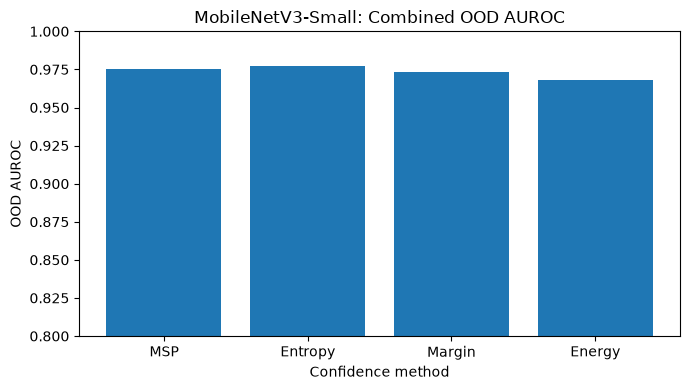

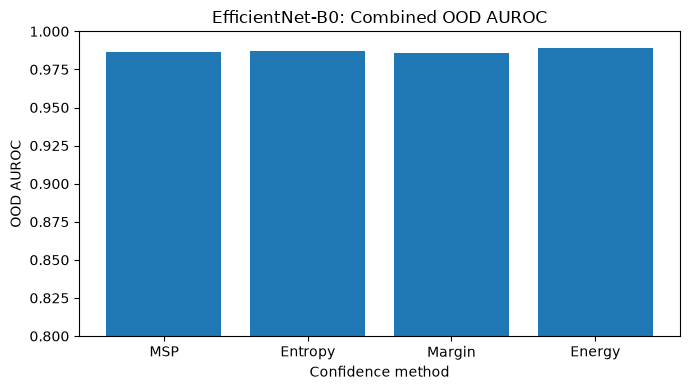

In [21]:
import matplotlib.pyplot as plt

plot_df = (
    posthoc_results[
        posthoc_results["ood_dataset"] == "Combined"
    ]
)

for model_name in plot_df["model"].unique():

    subset = plot_df[
        plot_df["model"] == model_name
    ]

    plt.figure(figsize=(7, 4))

    plt.bar(
        subset["method"],
        subset["auroc"],
    )

    plt.ylim(0.8, 1.0)

    plt.xlabel("Confidence method")
    plt.ylabel("OOD AUROC")
    plt.title(
        f"{model_name}: Combined OOD AUROC"
    )

    plt.tight_layout()
    plt.show()

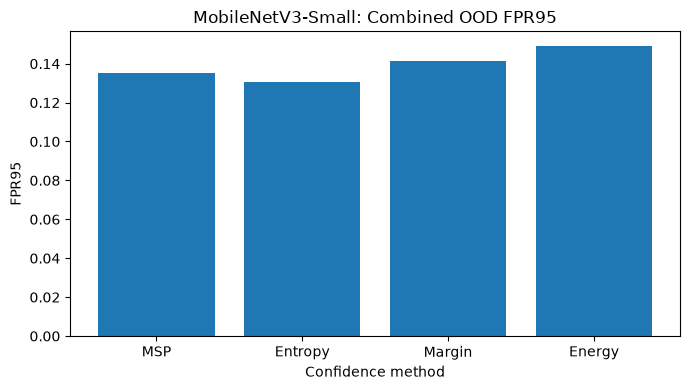

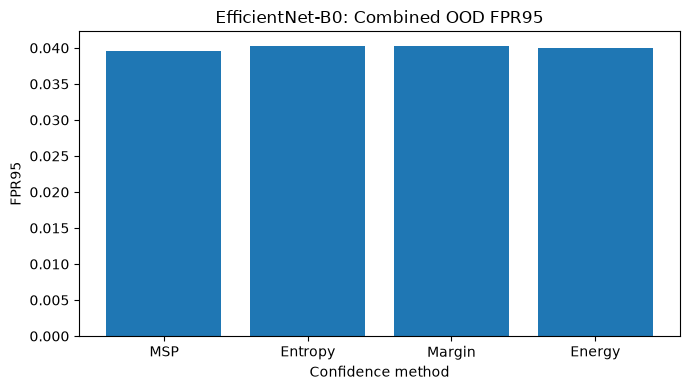

In [22]:
for model_name in plot_df["model"].unique():

    subset = plot_df[
        plot_df["model"] == model_name
    ]

    plt.figure(figsize=(7, 4))

    plt.bar(
        subset["method"],
        subset["fpr95"],
    )

    plt.xlabel("Confidence method")
    plt.ylabel("FPR95")
    plt.title(
        f"{model_name}: Combined OOD FPR95"
    )

    plt.tight_layout()
    plt.show()

In [25]:
species_results = posthoc_results[
    posthoc_results["ood_dataset"].isin(
        ["Grape", "Corn", "Nonplant"]
    )
]

species_results

,model,method,ood_dataset,auroc,aupr_id,fpr95,ood_rejection_at_95_id_coverage
0,MobileNetV3-Small,MSP,Grape,0.970766,0.988239,0.166420,0.833580
1,MobileNetV3-Small,MSP,Corn,0.979333,0.991960,0.105140,0.894860
2,MobileNetV3-Small,MSP,Nonplant,0.978324,0.998547,0.113333,0.885000
4,MobileNetV3-Small,Entropy,Grape,0.972422,0.988720,0.163712,0.836288
5,MobileNetV3-Small,Entropy,Corn,0.982216,0.992874,0.099688,0.900312
6,MobileNetV3-Small,Entropy,Nonplant,0.981158,0.998726,0.105000,0.895000
8,MobileNetV3-Small,Margin,Grape,0.969518,0.987845,0.170359,0.829394
9,MobileNetV3-Small,Margin,Corn,0.977004,0.991202,0.113967,0.886033
10,MobileNetV3-Small,Margin,Nonplant,0.976117,0.998406,0.118333,0.878333
12,MobileNetV3-Small,Energy,Grape,0.949663,0.976943,0.244215,0.755785


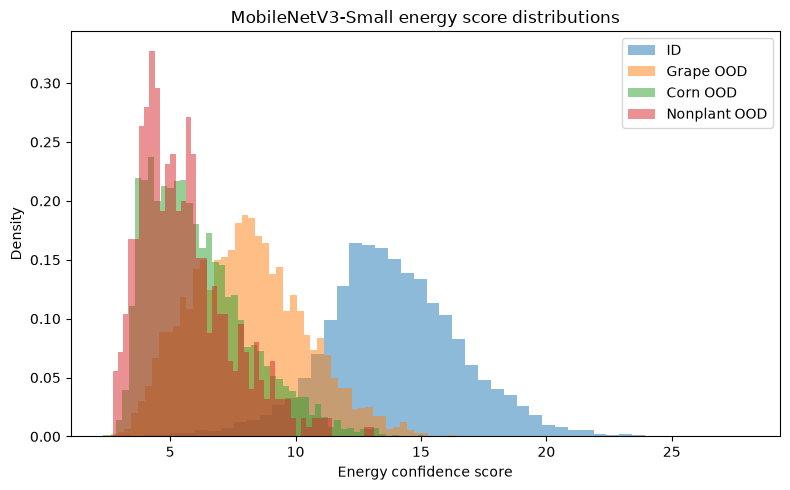

In [26]:
mobile_id_energy = energy_score(
    mobile_id["logits"]
)

mobile_grape_energy = energy_score(
    mobile_grape["logits"]
)

mobile_corn_energy = energy_score(
    mobile_corn["logits"]
)

mobile_nonplant_energy = energy_score(
    mobile_nonplant["logits"]
)

plt.figure(figsize=(8, 5))

plt.hist(
    mobile_id_energy,
    bins=50,
    alpha=0.5,
    density=True,
    label="ID",
)

plt.hist(
    mobile_grape_energy,
    bins=50,
    alpha=0.5,
    density=True,
    label="Grape OOD",
)

plt.hist(
    mobile_corn_energy,
    bins=50,
    alpha=0.5,
    density=True,
    label="Corn OOD",
)

plt.hist(
    mobile_nonplant_energy,
    bins=50,
    alpha=0.5,
    density=True,
    label="Nonplant OOD",
)

plt.xlabel("Energy confidence score")
plt.ylabel("Density")
plt.title(
    "MobileNetV3-Small energy score distributions"
)

plt.legend()
plt.tight_layout()
plt.show()